# Error Case Analysis



In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MultiLabelBinarizer
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.multiclass import OneVsRestClassifier
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", context="notebook", palette="muted")

# Paths (Adjusted for Kaggle Environment)
COMPETITION_DATA_ROOT = '/kaggle/input/competitions/birdclef-2026'
# Update the FEATURE_DATASET_PATH to wherever your merged parquet file is uploaded
FEATURE_DATASET_PATH  = '/kaggle/input/datasets/shuoyiyang/birdclef-features'

TRAIN_CSV = os.path.join(COMPETITION_DATA_ROOT, "train.csv")
INPUT_FEATURE_PATH = f'{FEATURE_DATASET_PATH}/BirdCLEF_Features/Noise_augmentation/features_v2_augmented.parquet'


print("Loading metadata...")
train_df = pd.read_csv(TRAIN_CSV)

print("Loading features...")
features_df = pd.read_parquet(INPUT_FEATURE_PATH)
print(f"Features loaded: {features_df.shape}")


Loading metadata...
Loading features...
Features loaded: (60808, 199)


## 2. Train / Validation Split
Using `GroupShuffleSplit` by `filename` to prevent data leakage from windowing.


In [ ]:
# Safe Classifier for rare classes
class SafeCalibratedSVC(BaseEstimator, ClassifierMixin):
    def __init__(self, base_estimator=None):
        self.base_estimator = base_estimator if base_estimator else LinearSVC(C=0.1, max_iter=2000, class_weight='balanced')
        
    def fit(self, X, y):
        self.classes_ = np.unique(y)
        if len(self.classes_) == 1:
            self.model_ = None
            self.majority_class_ = self.classes_[0]
            return self
            
        n_pos = np.sum(y == 1)
        if n_pos >= 3:
            self.model_ = CalibratedClassifierCV(self.base_estimator, cv=3)
        else:
            # Fallback to no CV calibration if too few samples
            self.model_ = CalibratedClassifierCV(self.base_estimator, cv="prefit")
            self.base_estimator.fit(X, y)
            
        self.model_.fit(X, y)
        return self
        
    def predict_proba(self, X):
        if hasattr(self, 'model_') and self.model_ is not None:
            return self.model_.predict_proba(X)
        else:
            probs = np.zeros((X.shape[0], 2))
            probs[:, int(self.majority_class_)] = 1.0
            return probs

meta_cols = ['filename', 'start_sec', 'site', 'hour']
feature_cols = [c for c in features_df.columns if c not in meta_cols]

X = features_df[feature_cols].values
X = np.nan_to_num(X)

# Labels
mlb = MultiLabelBinarizer()
train_df['primary_label'] = train_df['primary_label'].apply(lambda x: [x])
all_labels = mlb.fit_transform(train_df['primary_label'])
species_names = mlb.classes_

feat_filenames = features_df['filename'].values
file_to_label = {}
for orig_f, l in zip(train_df['filename'], all_labels):
    file_to_label[orig_f] = l                             # e.g., 'asbfly/XC12345.ogg'
    file_to_label[os.path.basename(orig_f)] = l           # e.g., 'XC12345.ogg'
    file_to_label[orig_f.replace('.ogg', '')] = l
    file_to_label[os.path.basename(orig_f).replace('.ogg', '')] = l

Y_list = []
matched_count = 0
for f in feat_filenames:
    if f in file_to_label:
        Y_list.append(file_to_label[f])
        matched_count += 1
    elif os.path.basename(str(f)) in file_to_label:
        Y_list.append(file_to_label[os.path.basename(str(f))])
        matched_count += 1
    else:
        Y_list.append(np.zeros(len(species_names)))

Y = np.array(Y_list)
print(f"Matched {matched_count} out of {len(feat_filenames)} features to labels.")
if matched_count == 0:
    print("WARNING: Label mapping failed! Sample feature filename:", feat_filenames[0])
    print("Sample train_df filename:", train_df['filename'].iloc[0])

# 80/20 Group Split
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, val_idx = next(gss.split(X, Y, groups=feat_filenames))

X_train, Y_train = X[train_idx], Y[train_idx]
X_val, Y_val = X[val_idx], Y[val_idx]
val_filenames = feat_filenames[val_idx]

print(f"Training samples: {len(X_train)}")
print(f"Validation samples: {len(X_val)}")


Matched 60808 out of 60808 features to labels.
Training samples: 48667
Validation samples: 12141


## 3. Training the SVM Model
Train the OneVsRest SVM model.


In [3]:
print("Scaling features...")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

print("Training OneVsRest SVM models (one per species)...")
base_svm = LinearSVC(C=0.1, max_iter=2000, class_weight='balanced', dual=False)

# We use n_jobs=-1 for speed. Warnings may appear but they are harmless.
clf = OneVsRestClassifier(SafeCalibratedSVC(base_estimator=base_svm), n_jobs=1)

import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    clf.fit(X_train_scaled, Y_train)
print("Training complete!")

print("Generating predictions on validation set...")
Y_pred_prob = clf.predict_proba(X_val_scaled)

# Safely compute Macro-AUC only for classes present in validation set
valid_aucs = []
for i in range(Y_val.shape[1]):
    if np.sum(Y_val[:, i]) > 0:
        valid_aucs.append(roc_auc_score(Y_val[:, i], Y_pred_prob[:, i]))

overall_auc = np.mean(valid_aucs) if valid_aucs else 0.0
print(f"Overall Validation Macro-AUC (on {len(valid_aucs)} present species): {overall_auc:.4f}")


Scaling features...
Training OneVsRest SVM models (one per species)...
Training complete!
Generating predictions on validation set...
Overall Validation Macro-AUC (on 176 present species): 0.8795


## 4. Error Identification: Hardest Species
Identifying species with lowest performance.


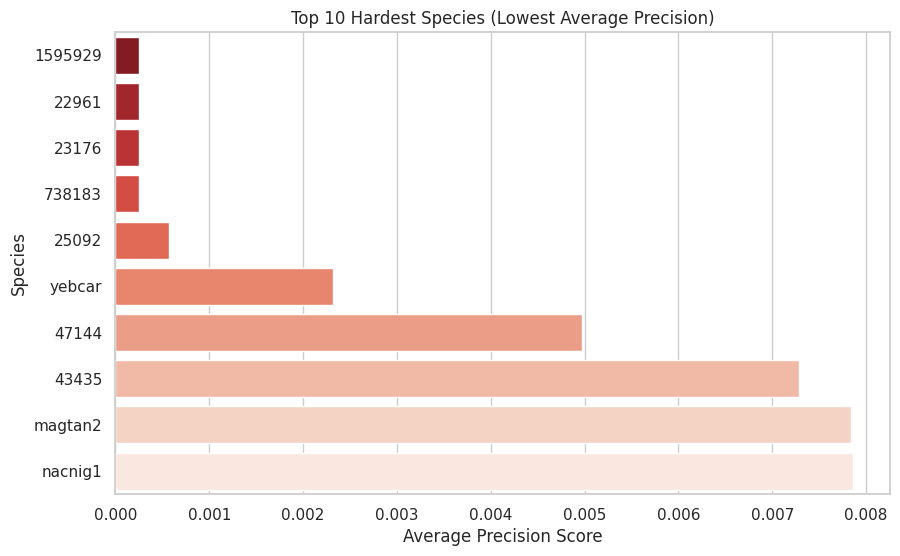

,species,train_count,ap,auc
0,1595929,0,0.000247,0.500000
1,22961,0,0.000247,0.500000
4,23176,0,0.000247,0.500000
15,738183,0,0.000247,0.500000
7,25092,4,0.000567,0.621959
171,yebcar,40,0.002319,0.731161
10,47144,6,0.004975,0.884825
9,43435,3,0.007281,0.882447
87,magtan2,149,0.007837,0.853902
89,nacnig1,20,0.007865,0.749687


In [ ]:
# Calculate Average Precision (AP) for each species
species_metrics = []

for i, sp in enumerate(species_names):
    y_true = Y_val[:, i]
    y_scores = Y_pred_prob[:, i]
    
    if np.sum(y_true) > 0:
        ap = average_precision_score(y_true, y_scores)
        auc = roc_auc_score(y_true, y_scores) if np.sum(y_true) < len(y_true) else 0.0
        train_count = np.sum(Y_train[:, i])
        species_metrics.append({
            'species': sp,
            'train_count': train_count,
            'val_count': np.sum(y_true),
            'ap': ap,
            'auc': auc
        })

metrics_df = pd.DataFrame(species_metrics)

# Top 10 Hardest Species
hardest_species = metrics_df[metrics_df['val_count'] > 0].sort_values('ap').head(10)

plt.figure(figsize=(10, 6))
sns.barplot(data=hardest_species, x='ap', y='species', palette='Reds_r')
plt.title("Top 10 Hardest Species (Lowest Average Precision)")
plt.xlabel("Average Precision Score")
plt.ylabel("Species")
plt.show()

display(hardest_species[['species', 'train_count', 'ap', 'auc']])


## 5. The Long-Tail Effect (Imbalance)


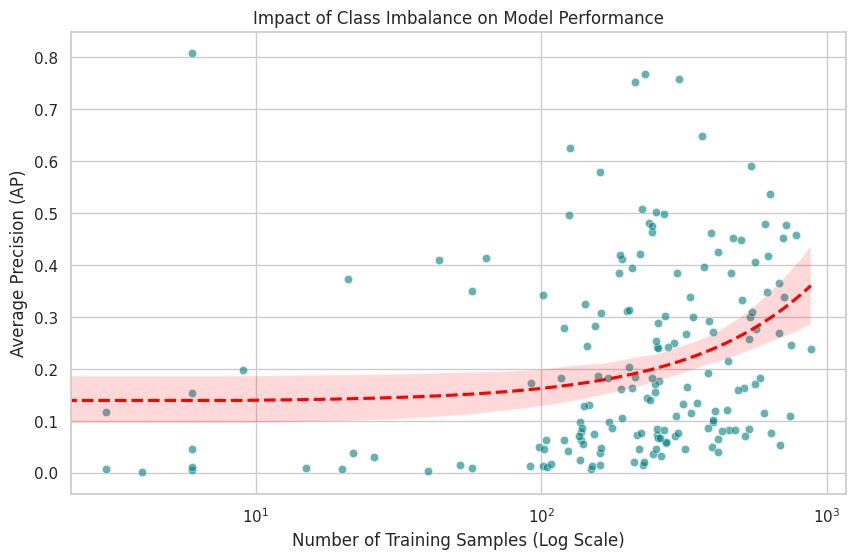

Pearson Correlation between Train Count and AP: 0.271
Strong positive correlation: lack of data for rare species degrades performance, necessitating data augmentation.


In [5]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=metrics_df, x='train_count', y='ap', alpha=0.6, color='teal')

# Add a trendline
sns.regplot(data=metrics_df, x='train_count', y='ap', scatter=False, color='red', line_kws={"linestyle":"--"})

plt.xscale('log')
plt.title("Impact of Class Imbalance on Model Performance")
plt.xlabel("Number of Training Samples (Log Scale)")
plt.ylabel("Average Precision (AP)")
plt.show()

correlation = metrics_df['train_count'].corr(metrics_df['ap'])
print(f"Pearson Correlation between Train Count and AP: {correlation:.3f}")
print("Strong positive correlation: lack of data for rare species degrades performance, necessitating data augmentation.")


## Audio Quality (Rating)


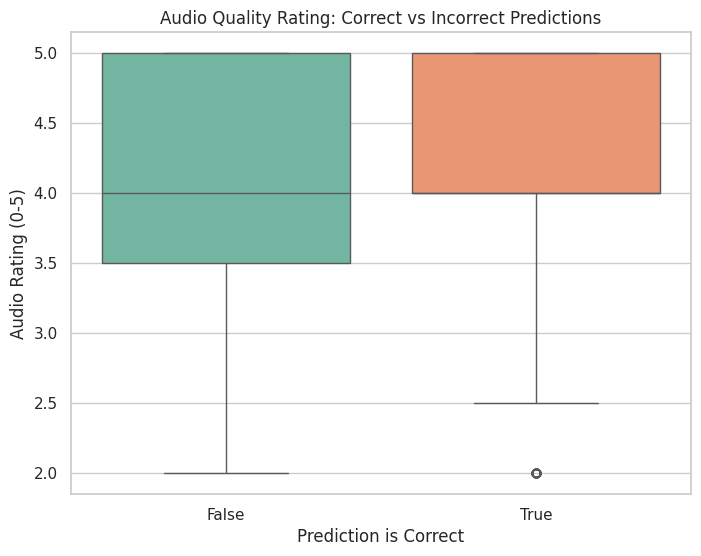

Mean Rating for Correct Predictions: 4.25
Mean Rating for Incorrect Predictions: 4.05
Misclassified samples generally have lower acoustic quality, validating the MIN_RATING >= 2.0 filter.


In [ ]:
# Get the top predicted species for each validation sample
pred_classes_idx = np.argmax(Y_pred_prob, axis=1)
true_classes_idx = np.argmax(Y_val, axis=1)

# Create an analysis dataframe
analysis_df = pd.DataFrame({
    'filename': val_filenames,
    'true_idx': true_classes_idx,
    'pred_idx': pred_classes_idx,
    'is_correct': true_classes_idx == pred_classes_idx
})

train_df['basename'] = train_df['filename'].apply(os.path.basename)
analysis_df['basename'] = analysis_df['filename'].apply(lambda x: os.path.basename(str(x)))

train_df_unique = train_df[['basename', 'rating']].drop_duplicates('basename')
analysis_df = analysis_df.merge(train_df_unique, on='basename', how='left')

analysis_df = analysis_df.dropna(subset=['rating'])

plt.figure(figsize=(8, 6))
sns.boxplot(data=analysis_df, x='is_correct', y='rating', palette='Set2')
plt.title("Audio Quality Rating: Correct vs Incorrect Predictions")
plt.xlabel("Prediction is Correct")
plt.ylabel("Audio Rating (0-5)")
plt.show()

correct_mean = analysis_df[analysis_df['is_correct']]['rating'].mean()
incorrect_mean = analysis_df[~analysis_df['is_correct']]['rating'].mean()

print(f"Mean Rating for Correct Predictions: {correct_mean:.2f}")
print(f"Mean Rating for Incorrect Predictions: {incorrect_mean:.2f}")
print("Misclassified samples generally have lower acoustic quality, validating the MIN_RATING >= 2.0 filter.")


## 7. Confusion Pairs
Identifying top confused bird pairs.


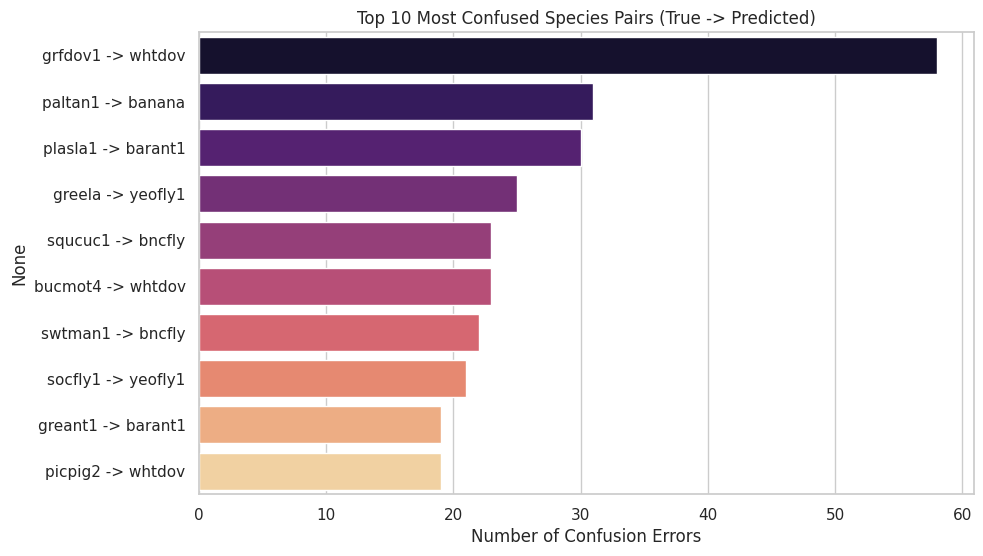

These pairs may share similar spectral shapes or co-occur in the same environments.


In [7]:
incorrect_df = analysis_df[~analysis_df['is_correct']]

confusion_pairs = []
for _, row in incorrect_df.iterrows():
    true_sp = species_names[row['true_idx']]
    pred_sp = species_names[row['pred_idx']]
    # We ignore predictions where the model predicted 'background' or 0 vectors
    if np.sum(Y_val[row.name]) > 0:
        confusion_pairs.append(f"{true_sp} -> {pred_sp}")

pair_counts = pd.Series(confusion_pairs).value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=pair_counts.values, y=pair_counts.index, palette='magma')
plt.title("Top 10 Most Confused Species Pairs (True -> Predicted)")
plt.xlabel("Number of Confusion Errors")
plt.show()

print("These pairs may share similar spectral shapes or co-occur in the same environments.")
